Import Libraries and Set Seeds

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import random, numpy as np
from google.colab import drive

#SEED = 42
## Set seeds for all random sources
#random.seed(SEED)        # Python built-in RNG
#np.random.seed(SEED)     # NumPy RNG
#tf.random.set_seed(SEED) # TensorFlow RNG

Import and Clean Data

In [2]:
#  Dataset paths
L1 = ''
L2 = ''
L3 = ''
L4 = ''

#  Load Training set
X_train = np.load(L1)
Y_train = np.load(L2)
# Load Dev set
X_val = np.load(L3)
Y_val = np.load(L4)

### Post Process --> remove Nans and Infinities (Some Vs30 Values may be Nan) --> Replace with site average
X_train_pre = np.nan_to_num(X_train, nan=0.0, posinf=0.0, neginf=0.0)
Y_train_pre = np.nan_to_num(Y_train, nan=0.0, posinf=0.0, neginf=0.0)
X_val_pre = np.nan_to_num(X_val,   nan=0.0, posinf=0.0, neginf=0.0)
Y_val_pre  = np.nan_to_num(Y_val,   nan=0.0, posinf=0.0, neginf=0.0)
#Post process X-train and Y-train
X_train = X_train_pre.copy()
channel_means = np.nanmean(X_train, axis=(1, 2), keepdims=True)
nan_mask = np.isnan(X_train)
X_train = np.where(nan_mask, channel_means, X_train)
Y_train = Y_train_pre.copy()
channel_means = np.nanmean(Y_train, axis=(1, 2), keepdims=True)
nan_mask = np.isnan(Y_train)
Y_train = np.where(nan_mask, channel_means, Y_train)
#Post process X-val and Y-val
X_val = X_val_pre.copy()
channel_means = np.nanmean(X_val, axis=(1, 2), keepdims=True)
nan_mask = np.isnan(X_val)
X_val = np.where(nan_mask, channel_means, X_val)
Y_val = Y_val_pre.copy()
channel_means = np.nanmean(Y_val, axis=(1, 2), keepdims=True)
nan_mask = np.isnan(Y_val)
Y_val = np.where(nan_mask, channel_means, Y_val)
# Check all Nans and infinities removed
print("X_train has NaN:", np.isnan(X_train).any(), "Inf:", np.isinf(X_train).any())
print("Y_train has NaN:", np.isnan(Y_train).any(), "Inf:", np.isinf(Y_train).any())
print("X_val has NaN:", np.isnan(X_val).any(), "Inf:", np.isinf(X_val).any())
print("Y_val has NaN:", np.isnan(Y_val).any(), "Inf:", np.isinf(Y_val).any())

#Check imported shapes
print(" ")
print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_val:", X_val.shape)
print("Y_val:", Y_val.shape)

Mounted at /content/drive
X_train has NaN: False Inf: False
Y_train has NaN: False Inf: False
X_val has NaN: False Inf: False
Y_val has NaN: False Inf: False
 
X_train: (2400, 75, 75, 5)
Y_train: (2400, 75, 75, 3)
X_val: (208, 75, 75, 5)
Y_val: (208, 75, 75, 3)


View some of the ground truth shakemaps before training

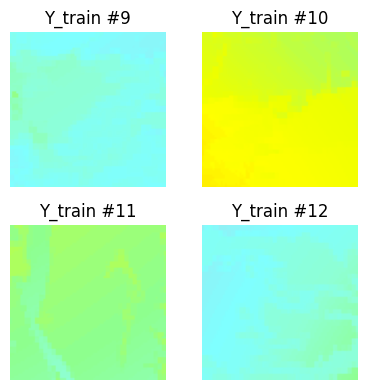

In [7]:
plt.figure(figsize=(4, 4))
for i in range(4):
    idx = i + 9    # starting index
    plt.subplot(2, 2, i + 1)
    plt.title(f"Y_train #{idx}")
    plt.imshow(Y_train[idx])
    plt.axis("off")
plt.tight_layout()
plt.show()

Build Model

In [ ]:
# Input and Output Volume Dimensions
H_in, W_in, C_in = X_train.shape[1:4]
H_out, W_out, C_out = Y_train.shape[1:4]

# Model definition
X = layers.Input(shape=(H_in, W_in, C_in))

# Add input normalization layer
norm_layer = layers.Normalization(axis=-1)  #Normalize Across Channels --> Each channel holds different kind of data
norm_layer.adapt(X_train)  # Compute per-channel mean and variance across entire training set
X_norm = norm_layer(X)  # Normalize the input

# Layer 1 Convolution
z1 = layers.Conv2D(32, 7, padding='same')(X_norm)
z1 = layers.BatchNormalization()(z1)
a1 = layers.Activation('relu')(z1)

# Layer 2 Convolution
z2 = layers.Conv2D(32, 5, padding='same')(a1)
z2 = layers.BatchNormalization()(z2)
a2 = layers.Activation('relu')(z2)

# Layer 3 Convolution
z3 = layers.Conv2D(32, 3, padding='same')(a2)
z3 = layers.BatchNormalization()(z3)
a3 = layers.Activation('relu')(z3)

# Layer 4 Convolution
z4 = layers.Conv2D(24, 5, padding='same')(a3)
z4 = layers.BatchNormalization()(z4)
a4 = layers.Activation('relu')(z4)

# Layer 5 Convolution
z5 = layers.Conv2D(24, 3, padding='same')(a4)
z5 = layers.BatchNormalization()(z5)
a5 = layers.Activation('relu')(z5)

# Layer 6 Convolution
z6 = layers.Conv2D(16, 3, padding='same')(a5)
z6 = layers.BatchNormalization()(z6)
a6 = layers.Activation('relu')(z6)

# Layer 7 Convolution
z7 = layers.Conv2D(16, 3, padding='same')(a6)
z7 = layers.BatchNormalization()(z7)
a7 = layers.Activation('relu')(z7)

# Layer 8 Convolution
z8 = layers.Conv2D(12, 3, padding='same')(a7)
z8 = layers.BatchNormalization()(z8)
a8 = layers.Activation('relu')(z8)

# Layer 9 (Output) Convolution
y_hats = layers.Conv2D(C_out, 1, activation='sigmoid', padding='same')(a8)

#Insantiate model
model = models.Model(inputs=X, outputs=y_hats)

Compile for training

In [12]:
# Compile
opt = tf.keras.optimizers.Adam(learning_rate=1e-3)   #Adam optimizer with alpha = 0.001
model.compile(optimizer = opt, loss = normalized_l2_RGB_channelwise_loss)   #Channel-wise Pixel Error Loss

# Inspect model
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 75, 75, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 75, 75, 5)      │            11 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 75, 75, 32)     │         7,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 75, 75, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 32)     │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 75, 75, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 75, 75, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 75, 75, 24)     │        19,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 75, 75, 24)     │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 75, 75, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 75, 75, 24)     │         5,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 75, 75, 24)     │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 75, 75, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 75, 75, 16)     │         3,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 75, 75, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 75, 75, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 75, 75, 16)     │            6

 Total params: 75,518 (295.00 KB)

 Trainable params: 75,131 (293.48 KB)

 Non-trainable params: 387 (1.52 KB)

Train Model and Cross Validate

In [13]:
# Training
BATCH_SIZE = 16
EPOCHS = 25

HISTORY = model.fit(
    X_train, Y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    validation_data=(X_val, Y_val)
)

Epoch 1/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 19s 29ms/step - loss: 0.2015 - val_loss: 0.1353
Epoch 2/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0976 - val_loss: 0.0854
Epoch 3/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0744 - val_loss: 0.0725
Epoch 4/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0675 - val_loss: 0.0578
Epoch 5/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0641 - val_loss: 0.0576
Epoch 6/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.0620 - val_loss: 0.0525
Epoch 7/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.0610 - val_loss: 0.0523
Epoch 8/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.0600 - val_loss: 0.0480
Epoch 9/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0592 - val_loss: 0.0461
Epoch 10/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0586 - val_loss: 0.0465
Epoch 11/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0581 - val_loss: 0.0462
Epoch 12/25
150/150 ━━━━━━━━━━━━━━━━━━━━

View Loss Graphs

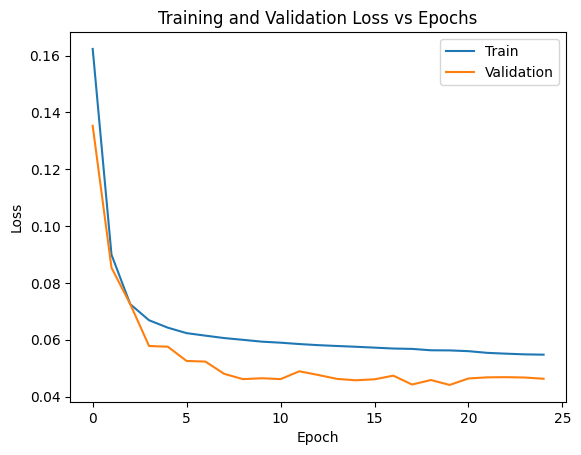

In [14]:
# Plot both training and validation losses
plt.plot(HISTORY.history['loss'], label='Train')
plt.plot(HISTORY.history['val_loss'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss vs Epochs')
plt.legend()
plt.show()

Evaluate Model via Performance Metrics


In [25]:
# Get predictions for training and validation sets with trained model
Y_pred_train = model.predict(X_train)
Y_pred_train = np.asarray(Y_pred_train)
Y_pred_val = model.predict(X_val)
Y_pred_val = np.asarray(Y_pred_val)

# Mean Score and STDV Score Evaluation
# Training
mad_train  = mad_eval(Y_train, Y_pred_train)
ssim_train = ssim_eval_batch(Y_train, Y_pred_train)
mad_mean_tr, mad_std_tr = mad_train
ssim_mean_tr, ssim_std_tr = ssim_train
mean_score_tr = 0.5 * (1 - mad_mean_tr) + 0.5 * ssim_mean_tr
std_score_tr  = 0.5 * mad_std_tr + 0.5 * ssim_std_tr

# Validation
mad_val  = mad_eval(Y_val, Y_pred_val)
ssim_val = ssim_eval_batch(Y_val, Y_pred_val)
mad_mean_val, mad_std_val = mad_val
ssim_mean_val, ssim_std_val = ssim_val
mean_score_val = 0.5 * (1 - mad_mean_val) + 0.5 * ssim_mean_val
std_score_val  = 0.5 * mad_std_val + 0.5 * ssim_std_val

#Print Results
print('')
print("Training Mean Score:", mean_score_tr)
print("Training STDV Score:", std_score_tr)
print('')
print("Validation Mean Score:", mean_score_val)
print("Validation STDV Score:", std_score_val)

75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

Training Mean Score: 0.9340084510296583
Training STDV Score: 0.04270836189389229

Validation Mean Score: 0.9463390357047319
Validation STDV Score: 0.04160931371152401


View a random validation set prediction from trained model

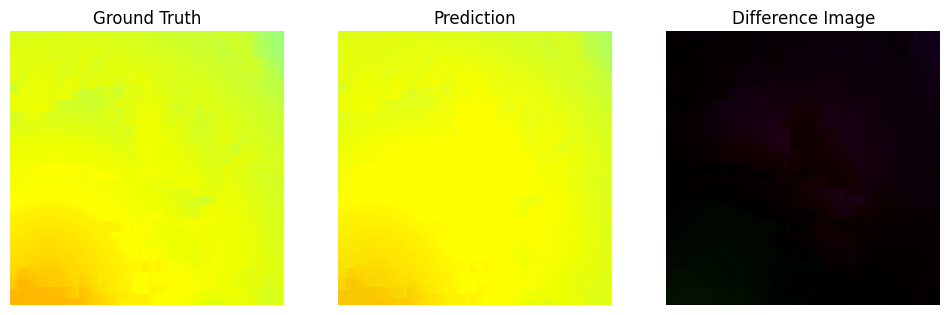

In [ ]:
# Pick a validation example randomly
i = np.random.randint(0, Y_val.shape[0])

# Get images for comparison
ground_truth = Y_val[i]
prediction = Y_pred_val[i]

# Difference image (absolute pixel-wise RGB difference)
diff = np.abs(ground_truth - prediction)

# Plot Results
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(ground_truth)
axes[0].set_title("Ground Truth")
axes[0].axis("off")

axes[1].imshow(prediction)
axes[1].set_title("Prediction")
axes[1].axis("off")

axes[2].imshow(diff)
axes[2].set_title("Difference Image")
axes[2].axis("off")

plt.tight_layout()
plt.show()

Initialize Loss Functions

In [10]:
###########   Pixel-wise RGB (flatten entire 250x250x3 image)  ###################
#|| y - y_hat ||_2  / ( || y ||_2 + eps )
@tf.function
def normalized_l2_RGB_loss(y_true, y_pred, eps=tf.constant(1e-8, dtype=tf.float32)):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    N = tf.shape(y_true)[0]    #number of samples in batch

    #Numerator --> Calculate element-wise difference (error) then flatten
    diff = tf.reshape(y_true - y_pred, [N, -1])
    numer = tf.sqrt(tf.reduce_sum(diff * diff, axis=1))    #L2 norm of difference
    #Denominator --> Normalization
    gtruth = tf.reshape(y_true, [N, -1])
    denom = tf.sqrt(tf.reduce_sum(gtruth * gtruth, axis=1)) + eps   #ground truth L2 norm

    #Calculate loss and batch cost
    per_example = numer / denom  #individual loss per example
    return tf.reduce_mean(per_example)  #Cost over batch


###########   Pixel-wise RGB (sum over channels)  ###################
#average [|| yc - yc_hat ||_2  / ( || yc ||_2 + eps )] over the three channels
@tf.function
def normalized_l2_RGB_channelwise_loss(y_true, y_pred, eps=tf.constant(1e-8, dtype=tf.float32)):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    #Difference between y_pred and y_hat pixels
    diff = y_true - y_pred                     # (B, H, W, 3)

    #Numerator --> average of channel-wise difference L2 norm
    numer = tf.sqrt(tf.reduce_sum(diff * diff, axis=[1, 2]))             # (B, 3)
    numer = tf.reduce_mean(numer, axis=1)

    #Denominator --> Normalization by global (denominator is not channel wise) ground truth L2 norm
    N = tf.shape(y_true)[0]    #number of samples in batch
    gtruth = tf.reshape(y_true, [N, -1])
    denom = tf.sqrt(tf.reduce_sum(gtruth * gtruth, axis=1)) + eps

    #Calculate loss and batch cost
    per_example = numer / denom  #individual loss per example
    return tf.reduce_mean(per_example)  #Cost over batch


########## SSIM Loss #################
def ssim_loss_tf(y_true, y_pred, max_val=1.0):
    """
    Computes SSIM loss using TensorFlow's built-in SSIM.

    y_true, y_pred: (B, H, W, C), pixel values expected in [0, max_val]
    Returns: scalar loss = 1 - mean(SSIM)
    """
    # Cast to float
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    # Built-in SSIM → (B,)
    ssim_vals = tf.image.ssim(y_true, y_pred, max_val=max_val)

    # Convert similarity to loss → scalar
    return 1.0 - tf.reduce_mean(ssim_vals)

########## Combined Loss ##########
"""
Combined channel-wise RGB pixel loss and SSIM loss. Weights of 0.75 and 0.25, respectively
"""
def combined_rgb_ssim_loss(y_true, y_pred, w_pix=0.75, w_ssim=0.25):
    L_pix  = normalized_l2_RGB_channelwise_loss(y_true, y_pred)
    L_ssim = ssim_loss_tf(y_true, y_pred)
    return w_pix * L_pix + w_ssim * L_ssim

Initialize Evaluation Metric Functions

In [11]:
########### Mean and STDV Absolute RGB Pixel Difference ###########
"""
Difference vector between flattened ground-truth vector and flattened prediction.
Then average absolute difference across the three channels for a single scalar value.
Average this scalar value from each of the training examples across the dataset,
and get STDV.
"""
def mad_eval(y_true, y_pred):
    per_img_mae = np.mean(np.abs(y_true - y_pred), axis=(1,2,3))
    M = float(np.mean(per_img_mae))   #Mean
    S = float(np.std(per_img_mae))  #STDV
    return M,S


########### Meand and STDV SSIM Across Dataset ###########
"""
Calculate SSIM between ground truth image and prediction. Then average SSIM's
across the dataset and get STDV.
"""
def ssim_eval(y_true, y_pred):
    ssim_vals = tf.image.ssim(tf.cast(y_true, tf.float32), tf.cast(y_pred, tf.float32), max_val=1.0).numpy()
    M = float(np.mean(ssim_vals))
    S = float(np.std(ssim_vals))
    return M,S

def ssim_eval_batch(y_true, y_pred, batch_size=32):
    ssim_list = []
    N = y_true.shape[0]

    for i in range(0, N, batch_size):
        y_t = y_true[i:i+batch_size]
        y_p = y_pred[i:i+batch_size]

        vals = tf.image.ssim(tf.cast(y_t, tf.float32),tf.cast(y_p, tf.float32),max_val=1.0).numpy()
        ssim_list.append(vals)

    ssim_vals = np.concatenate(ssim_list)
    return float(np.mean(ssim_vals)), float(np.std(ssim_vals))
